# 00 · EDA

What the gold answers look like (length, style) and how the data is spread over countries and categories.
Uses the `qa` jsonl files only, no images.

- Only train and dev have gold answers (devtest answers are hidden). **No split has `country` / `category` fields**, so section 3 uses a text-based proxy.
- To get train jsonl without the image zips: `python download_data.py train --task qa --no-media`


In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from data import RESULTS_DIR, load_split, split_path

pd.set_option("display.max_colwidth", 200)

frames = []
for split in ("train", "dev", "devtest"):
    if split_path("qa", split).exists():
        frames.append(pd.DataFrame(load_split("qa", split)))
    else:
        print(f"skip {split}: {split_path('qa', split)} not found")
df = pd.concat(frames, ignore_index=True)
df = df[df["answer"].notna()].reset_index(drop=True)  # devtest has no gold answers
print(df.groupby("split").size())
print("columns:", list(df.columns))

split
dev       1000
train    10000
dtype: int64
columns: ['id', 'image', 'question', 'answer', 'row_idx', 'lang', 'split', 'image_path']


## 1. Length of answers and questions

In [2]:
def n_words(s): return len(s.split())
def n_sents(s): return max(1, len(re.findall(r"[.!?](?:\s|$)", s.strip())))

df["a_words"] = df["answer"].map(n_words)
df["q_words"] = df["question"].map(n_words)
df["a_sents"] = df["answer"].map(n_sents)

def describe(col):
    return df.groupby("split")[col].describe(percentiles=[.05, .25, .5, .75, .95]).round(1)

print("Answer length, words"); display(describe("a_words"))
print("Question length, words"); display(describe("q_words"))
print("Sentences per answer"); display(pd.crosstab(df["split"], df["a_sents"].clip(upper=3), normalize="index").round(3))

Answer length, words


,count,mean,std,min,5%,25%,50%,75%,95%,max
split,,,,,,,,,,
dev,1000.0,25.2,8.8,3.0,13.0,19.0,24.0,30.0,41.0,63.0
train,10000.0,24.5,9.1,1.0,12.0,18.0,24.0,30.0,40.0,78.0


Question length, words


,count,mean,std,min,5%,25%,50%,75%,95%,max
split,,,,,,,,,,
dev,1000.0,14.9,3.0,8.0,10.0,13.0,15.0,17.0,20.0,25.0
train,10000.0,14.8,3.0,6.0,10.0,13.0,15.0,17.0,20.0,30.0


Sentences per answer


a_sents,1,2,3
split,,,
dev,0.761,0.233,0.006
train,0.780,0.211,0.009


In [3]:
from transformers import AutoTokenizer  # already installed for bert_score
tok = AutoTokenizer.from_pretrained("roberta-large")  # only used to count tokens, not the scorer model
df["a_tokens"] = [len(x) - 2 for x in tok(df["answer"].tolist())["input_ids"]]  # minus <s>, </s>
print("Answer length, roberta tokens"); display(df.groupby("split")["a_tokens"].describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
print("tokens / word:", (df["a_tokens"].sum() / df["a_words"].sum()).round(2))


Answer length, roberta tokens


,count,mean,std,min,5%,25%,50%,75%,95%,max
split,,,,,,,,,,
dev,1000.0,31.5,10.9,6.0,16.0,24.0,30.0,38.0,52.0,71.0
train,10000.0,30.8,11.4,2.0,15.0,23.0,29.0,37.0,51.0,92.0


tokens / word: 1.26


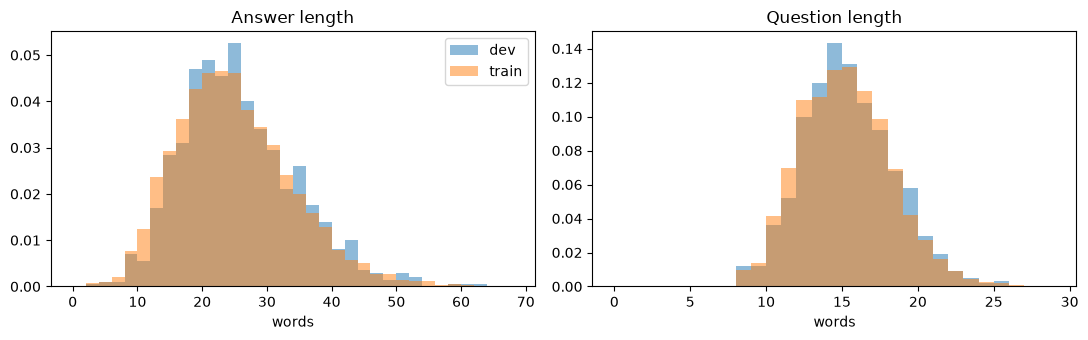

corr(question words, answer words): 0.3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for split, g in df.groupby("split"):
    axes[0].hist(g["a_words"], bins=range(0, 70, 2), alpha=.5, density=True, label=split)
    axes[1].hist(g["q_words"], bins=range(0, 30), alpha=.5, density=True, label=split)
axes[0].set(title="Answer length", xlabel="words")
axes[1].set(title="Question length", xlabel="words")
axes[0].legend()
plt.tight_layout(); plt.show()

print("corr(question words, answer words):", df[["q_words", "a_words"]].corr().iloc[0, 1].round(2))

## 2. Answer style

In [5]:
STOP = {"the", "a", "an", "of", "in", "is", "are", "what", "which", "this", "these", "that", "and", "to",
        "for", "on", "with", "does", "do", "image", "shown", "picture", "photo", "by", "be", "can"}
def content(s): return set(re.findall(r"[a-z']+", s.lower())) - STOP

HEDGE = r"\b(?:likely|possibly|probably|may|might|suggests?|appears?|seems?)\b"
IMAGE_REF = r"\b(?:the image|this image|the photo|the picture|depicted|shown|visible|in the background)\b"

a = df["answer"].str.strip()
style = pd.DataFrame({
    "split": df["split"],
    "starts_with_The": a.str.startswith("The "),
    "ends_with_period": a.str.endswith("."),
    "full_sentence": a.str.contains(r"\b(?:is|are|was|were|has|have|shows?|depicts?|represents?)\b", case=False),
    "mentions_image": a.str.contains(IMAGE_REF, case=False),
    "hedging": a.str.contains(HEDGE, case=False),
    "yes_no": a.str.lower().str.match(r"^(yes|no)\b"),
})
display(style.groupby("split").mean().round(3))

df["q_overlap"] = [len(content(x) & content(q)) / max(1, len(content(q))) for x, q in zip(df["answer"], df["question"])]
print("Share of question content words repeated in the answer:", df.groupby("split")["q_overlap"].mean().round(2).to_dict())

,starts_with_The,ends_with_period,full_sentence,mentions_image,hedging,yes_no
split,,,,,,
dev,0.939,0.995,0.769,0.263,0.250,0.0
train,0.952,0.993,0.763,0.258,0.217,0.0


Share of question content words repeated in the answer: {'dev': 0.43, 'train': 0.43}


In [6]:
print("Most common answer openings (first 2 words):")
display(df["answer"].str.split().str[:2].str.join(" ").value_counts().head(15).to_frame("count"))
print("Most common question openings (first 2 words):")
display(df["question"].str.split().str[:2].str.join(" ").value_counts().head(15).to_frame("count"))

Most common answer openings (first 2 words):


,count
answer,
The image,1576
The building,367
The mosque,305
The flag,275
The person,202
The flags,174
The individuals,168
The gathering,153
The event,144


Most common question openings (first 2 words):


,count
question,
What is,3199
What type,1250
What architectural,991
What does,811
What cultural,651
What types,400
What are,383
What historical,276
What traditional,264


In [7]:
def qtype(q):
    q = q.lower()
    for k, pat in [("significance/meaning", r"significan|symboli|meaning|represent"), ("cultural/traditional", r"cultur|tradition|heritage"),
                   ("identify (what is/which/who)", r"^(what|which|who)\b.*\b(is|are|name|type|kind)\b")]:
        if re.search(pat, q): return k
    return "other"
df["qtype"] = df["question"].map(qtype)
display(df.groupby(["split", "qtype"]).agg(n=("a_words", "size"), words=("a_words", "median"), tokens=("a_tokens", "median")).round(1))
print("share of answers with a comma-joined 2nd clause (', and|which|reflecting|...):",
      df["answer"].str.contains(r", (?:and|which|reflecting|representing|making|showing|as)\b").mean().round(2))


n  words  tokens
split qtype                                            
dev   cultural/traditional           128   25.0    31.0
      identify (what is/which/who)   435   20.0    26.0
      other                          131   25.0    31.0
      significance/meaning           306   30.0    36.0
train cultural/traditional          1089   24.0    31.0
      identify (what is/which/who)  4410   20.0    25.0
      other                         1059   24.0    30.0
      significance/meaning          3442   29.0    35.0

share of answers with a comma-joined 2nd clause (', and|which|reflecting|...): 0.55


In [8]:
dev = df[df["split"] == "dev"] if (df["split"] == "dev").any() else df
for name, part in [("shortest", dev.nsmallest(5, "a_words")), ("median", dev[dev["a_words"] == dev["a_words"].median()].head(3)), ("longest", dev.nlargest(3, "a_words"))]:
    print(f"--- {name}")
    for _, r in part.iterrows():
        print(f"[{r.a_words}w] Q: {r.question}\n      A: {r.answer}\n")

--- shortest
[3w] Q: What is the name of the iconic skyscraper visible in the background of this Dubai cityscape?
      A: The Burj Khalifa.

[5w] Q: What airline is represented by the airplane shown in the image?
      A: The airplane represents Qatar Airways.

[5w] Q: What is the prominent architectural landmark visible in the background of this waterfront scene?
      A: The Bahrain World Trade Center.

[7w] Q: What kind of fruit is prominently displayed in the market in this historic photograph of Mosul?
      A: Watermelons are prominently displayed in the market.

[7w] Q: What is the name of the perfume displayed on the bottle in the image?
      A: The name of the perfume is 'SERENITY'.

--- median
[24w] Q: What cultural or artistic significance do the sand art bottles in the image hold?
      A: The sand art bottles represent traditional Middle Eastern craftsmanship and are popular souvenirs from Dubai, showcasing desert landscapes, camels, and the region's natural beauty.

[24

## 3. Countries, categories, subcategories

The released jsonl has no `country` / `category` fields in any split (the code below runs if they appear). Proxy: country names and cities mentioned in the question or answer.

In [9]:
labeled = df[df["country"].notna()] if "country" in df else df.iloc[0:0]
if labeled.empty:
    print("No country / category labels loaded. The released jsonl (train, dev, devtest) has no such fields; see the place-name proxy below.")
else:
    for col in ("country", "category"):
        t = pd.crosstab(labeled[col], labeled["split"])
        t["share"] = (t.sum(axis=1) / t.values.sum()).round(3)
        display(t.sort_values("share", ascending=False))
    print("subcategories:", labeled["subcategory"].nunique())
    display(labeled["subcategory"].value_counts().head(20).to_frame("count"))

No country / category labels loaded. The released jsonl (train, dev, devtest) has no such fields; see the place-name proxy below.


In [10]:
if not labeled.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    labeled["country"].value_counts().sort_values().plot.barh(ax=axes[0], title="Examples per country")
    labeled["category"].value_counts().sort_values().plot.barh(ax=axes[1], title="Examples per category")
    plt.tight_layout(); plt.show()

    print("Answer length (words) by category")
    display(labeled.groupby("category")["a_words"].agg(["count", "mean", "median"]).round(1).sort_values("mean"))
    print("Category x country (counts)")
    display(pd.crosstab(labeled["category"], labeled["country"]))

In [11]:
# Dev has no labels: rough country guess from names in the question / answer text.
PLACES = {
    "Egypt": ["egypt", "cairo", "giza", "luxor", "alexandria", "aswan"],
    "UAE": ["uae", "emirat", "dubai", "abu dhabi", "sharjah"],
    "Saudi Arabia": ["saudi", "riyadh", "mecca", "makkah", "medina", "jeddah"],
    "Qatar": ["qatar", "doha"], "Bahrain": ["bahrain", "manama"], "Kuwait": ["kuwait"],
    "Oman": ["oman", "muscat"], "Yemen": ["yemen", "sanaa", "aden"],
    "Iraq": ["iraq", "baghdad", "mosul", "najaf", "karbala", "basra", "erbil"],
    "Syria": ["syria", "damascus", "aleppo", "palmyra"],
    "Lebanon": ["leban", "beirut", "byblos", "baalbek"], "Jordan": ["jordan", "amman", "petra"],
    "Palestine": ["palestin", "gaza", "jerusalem", "ramallah", "bethlehem"],
    "Morocco": ["morocc", "marrakech", "fez", "casablanca", "rabat"],
    "Algeria": ["alger", "algiers"], "Tunisia": ["tunis"], "Libya": ["libya", "tripoli", "benghazi"],
    "Sudan": ["sudan", "khartoum"],
}
def guess_countries(text):
    t = text.lower()
    return [c for c, keys in PLACES.items() if any(re.search(r"\b" + re.escape(k), t) for k in keys)]

dev = df[df["split"] == "dev"].copy()
if len(dev):
    dev["countries_named"] = (dev["question"] + " " + dev["answer"]).map(guess_countries)
    named = Counter(c for cs in dev["countries_named"] for c in cs)
    print(f"dev: {(dev['countries_named'].str.len() > 0).mean():.0%} of examples name a country or city")
    display(pd.Series(named).sort_values(ascending=False).to_frame("dev examples"))
    print(f"examples where a place is named only in the answer, not the question: "
          f"{sum(bool(set(guess_countries(a)) - set(guess_countries(q))) for q, a in zip(dev.question, dev.answer))}")

dev: 33% of examples name a country or city


,dev examples
Egypt,35
Qatar,30
Morocco,27
UAE,27
Palestine,26
Saudi Arabia,24
Jordan,21
Kuwait,19
Bahrain,19
Yemen,18


examples where a place is named only in the answer, not the question: 278


## 4. Save stats

In [12]:
stats = {
    "rows": df.groupby("split").size().to_dict(),
    "answer_words": df.groupby("split")["a_words"].describe().round(1).to_dict(orient="index"),
    "style": style.groupby("split").mean().round(3).to_dict(orient="index"),
}
if not labeled.empty:
    stats["country"] = labeled["country"].value_counts().to_dict()
    stats["category"] = labeled["category"].value_counts().to_dict()
RESULTS_DIR.mkdir(exist_ok=True)
pd.Series(stats).to_json(RESULTS_DIR / "data_stats.json", indent=2)
print("saved", RESULTS_DIR / "data_stats.json")

saved /Users/mohinska/Desktop/mmculture-qa/results/data_stats.json


## 5. Findings (dev, 1000 examples; train, 10k, matches within 1 word)

- **Gold answers are full sentences, not short phrases.** Median 24 words / 30 roberta tokens (5-95%: 13-41 words, 16-52 tokens; ~1.26 tokens per word). 76% one sentence, 23% two. 94% start with "The ...", 99.5% end with a period; 55% add a trailing clause (", and ...", ", which ...", ", reflecting ...").
- **Length follows the question type.** "Significance / symbolism / meaning" questions: median 30 words; "What is / which / name" identification questions: 20 words; descriptive "other": 25. Correlation of question and answer length: 0.3. The shortest golds (3-7 words, e.g. "The Burj Khalifa.") are rare name questions.
- **Answers restate the question:** ~43% of the question's content words come back. Openings: "The image ..." (15%), "The building / mosque / flag / person ...". 26% refer to the image, 25% hedge ("likely", "may", "suggests"), often with a closing line of cultural context. Never yes/no.
- **Questions are "What ...?"** ("What is" 32%, "What type" 12%, "What architectural" 10%, "What does" 8%, "What cultural" 7%), 15 words on average.
- **No country / category labels exist** in train, dev or devtest (devtest also has no answers). Per-country / per-category error analysis needs our own tagging. Place-name proxy on dev: 33% of examples name a place (Egypt 35, Qatar 30, Morocco 27, UAE 27, Palestine 26, Saudi Arabia 24 lead; 17 countries total), and in 278 of ~330 the place is **only in the answer**, so the model must recognise it from the image.

**Prompt rules for T2_Text (gold-style answers):**

- Target **1-2 sentences, ~20-30 words (<= ~40 tokens)**; hard cap ~45 words. Not one word, not a paragraph. Identification questions: ~20 words; significance questions: ~30.
- **Start with "The <subject> ..."**, restating the question's subject in a declarative sentence ("The airline featured is Kuwait Airways, ..."). No "Yes/No", no "Answer:", no bullet points, no markdown, end with a period.
- **Name the specific entity** (landmark, dish, airline, city, country) and add one clause of cultural context ("..., representing the national identity of Kuwait").
- Mild hedging ("likely", "suggests") is in-style where the image is ambiguous; do not refuse or describe uncertainty at length.
- Next: check with `bertscore()` on the dev subset how short / medium / long answers score against gold (e.g. "Qatar Airways" vs "The airplane represents Qatar Airways.").
